In [ ]:
import warnings

In [ ]:
warnings.filterwarnings("ignore")

In [ ]:
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
import tensorflow as tf

In [ ]:
from tensorflow.keras.datasets import mnist

In [ ]:
from tensorflow.keras.utils import to_categorical

In [ ]:
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
X_train_cnn = X_train_raw.astype('float32')

In [ ]:
X_test_cnn = X_test_raw.astype('float32')

In [ ]:
X_train_cnn = np.expand_dims(X_train_cnn, -1)

In [ ]:
X_test_cnn = np.expand_dims(X_test_cnn, -1)

In [ ]:
y_train_cnn = to_categorical(y_train_raw, 10)

In [ ]:
y_test_cnn = to_categorical(y_test_raw, 10)

In [ ]:
print("MNIST Image Dataset loaded successfully.")
print(f"  Training features shape: {X_train_cnn.shape} | Test features shape: {X_test_cnn.shape}")

MNIST Image Dataset loaded successfully.
  Training features shape: (60000, 28, 28, 1) | Test features shape: (10000, 28, 28, 1)


Task-1.2

In [ ]:
from tensorflow.keras.models import Sequential

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
cnn_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
   Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
     Flatten(),
     Dense(128, activation='relu'),
    Dropout(0.25),
    Dense(10, activation='softmax')
])

In [ ]:
print("CNN Architecture successfully established:")
cnn_model.summary()

CNN Architecture successfully established:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Task-1.3

In [ ]:
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
print("CNN model compiled successfully with Adam optimizer.")

CNN model compiled successfully with Adam optimizer.


Task-1.4

In [23]:
history_cnn = cnn_model.fit(
    X_train_cnn,
    y_train_cnn,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9826 - loss: 0.0589 - val_accuracy: 0.9873 - val_loss: 0.0419
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 54ms/step - accuracy: 0.9858 - loss: 0.0465 - val_accuracy: 0.9880 - val_loss: 0.0463
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - accuracy: 0.9856 - loss: 0.0454 - val_accuracy: 0.9872 - val_loss: 0.0529
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 55ms/step - accuracy: 0.9870 - loss: 0.0423 - val_accuracy: 0.9897 - val_loss: 0.0397
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 54ms/step - accuracy: 0.9877 - loss: 0.0371 - val_accuracy: 0.9892 - val_loss: 0.0463


In [24]:
print("\nCNN training complete.")


CNN training complete.


Task-1.5

In [25]:
from sklearn.metrics import classification_report, confusion_matrix

In [26]:
import seaborn as sns

In [27]:
import matplotlib.pyplot as plt

In [28]:
test_loss, test_acc = cnn_model.evaluate(X_test_cnn, y_test_cnn, verbose=0)

In [29]:
print(f"CNN Holdout Test Accuracy: {test_acc * 100:.2f}%\n")

CNN Holdout Test Accuracy: 98.71%



In [30]:
y_pred_probs = cnn_model.predict(X_test_cnn)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step


In [31]:
y_pred_classes = np.argmax(y_pred_probs, axis=1)

In [32]:
print("--- Classification Performance Report ---")
print(classification_report(y_test_raw, y_pred_classes))

--- Classification Performance Report ---
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.98      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.96      1.00      0.98      1028
           8       0.99      0.97      0.98       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



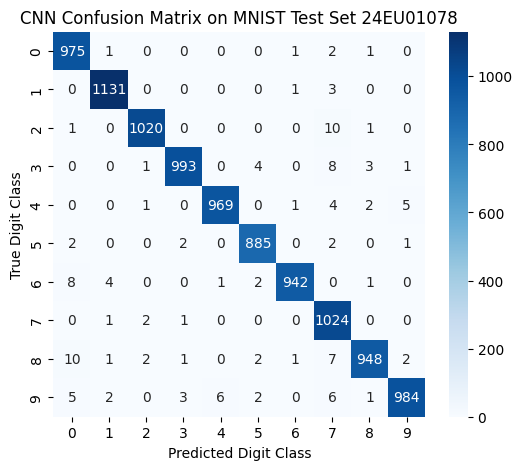

In [33]:
cm = confusion_matrix(y_test_raw, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title("CNN Confusion Matrix on MNIST Test Set 24EU01078")
plt.xlabel("Predicted Digit Class")
plt.ylabel("True Digit Class")
plt.show()

Task-2.1

In [34]:
import warnings

In [35]:
warnings.filterwarnings("ignore")

In [36]:
import numpy as np

In [37]:
import matplotlib.pyplot as plt

In [38]:
t_points = np.linspace(0, 100, 1000)

In [39]:
series_data = np.sin(t_points)

In [40]:
def create_sliding_windows(data, lookback=20):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback)])
        y.append(data[i + lookback])
    return np.array(X), np.array(y)

In [41]:
lookback_steps = 20
X_raw, y_raw = create_sliding_windows(series_data, lookback_steps)

In [42]:
X_seq = np.expand_dims(X_raw, -1)
y_seq = y_raw

In [43]:
split_idx = int(0.8 * len(X_seq))
X_train_seq, X_test_seq = X_seq[:split_idx], X_seq[split_idx:]
y_train_seq, y_test_seq = y_seq[:split_idx], y_seq[split_idx:]

In [44]:
print("Time Series Sequence Prepared:")
print(f"  Training features shape: {X_train_seq.shape} | Test features shape: {X_test_seq.shape}")

Time Series Sequence Prepared:
  Training features shape: (784, 20, 1) | Test features shape: (196, 20, 1)


Task-2.2

In [45]:
from tensorflow.keras.models import Sequential

In [46]:
from tensorflow.keras.layers import Dense, LSTM

In [47]:
lstm_model = Sequential([
    LSTM(50, activation='tanh', input_shape=(lookback_steps, 1)),
    Dense(1) # Linear continuous numeric output node
])

In [48]:
print("Sequential LSTM Architecture established:")
lstm_model.summary()

Sequential LSTM Architecture established:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Task-2.3

In [49]:
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

In [50]:
history_lstm = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("\nModel training complete.")

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.2469 - val_loss: 0.1261
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0530 - val_loss: 0.0023
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0026 - val_loss: 0.0012
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 7.9439e-04 - val_loss: 5.2076e-04
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.6147e-04 - val_loss: 3.1280e-04
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2.8913e-04 - val_loss: 2.6624e-04
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.5161e-04 - val_loss: 2.5086e-04
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 2.3541e-04 - val_loss: 1.7297e-04
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 1.7972e-04 - val_loss: 1.2269e-04
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 1.2641e-04 - val_loss: 1.0951e-04
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 9.5828e-05 - val_loss: 8.1804e-05

Taask-2.4

In [51]:
lstm_predictions = lstm_model.predict(X_test_seq)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


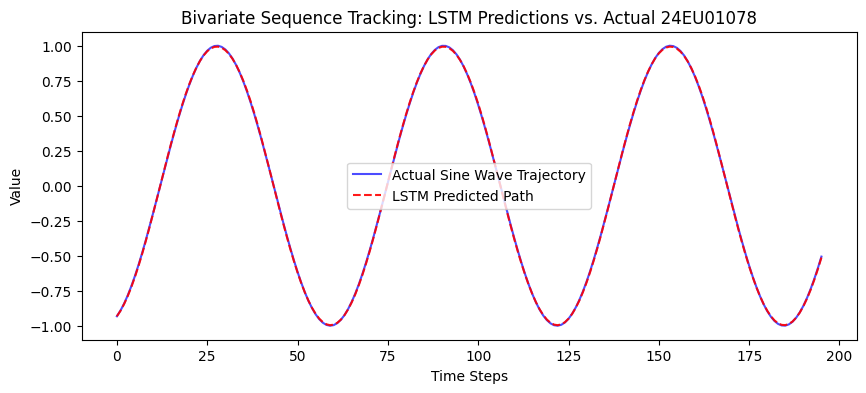

In [52]:
plt.figure(figsize=(10, 4))
plt.plot(y_test_seq, label='Actual Sine Wave Trajectory', color='blue', alpha=0.7)
plt.plot(lstm_predictions, label='LSTM Predicted Path', color='red', linestyle='--', alpha=0.9)
plt.title("Bivariate Sequence Tracking: LSTM Predictions vs. Actual 24EU01078")
plt.xlabel("Time Steps")
plt.ylabel("Value")
plt.legend()
plt.show()

Task-2.5

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [54]:
mae_lstm = mean_absolute_error(y_test_seq, lstm_predictions)
mse_lstm = mean_squared_error(y_test_seq, lstm_predictions)
r2_lstm = r2_score(y_test_seq, lstm_predictions)

In [55]:
print("--- LSTM Quantitative Performance ---")
print(f"Mean Absolute Error (MAE): {mae_lstm:.6f}")
print(f"Mean Squared Error (MSE):  {mse_lstm:.6f}")
print(f"Coefficient of Determination (R2): {r2_lstm:.6f}")

--- LSTM Quantitative Performance ---
Mean Absolute Error (MAE): 0.004134
Mean Squared Error (MSE):  0.000022
Coefficient of Determination (R2): 0.999957


Task-3.1

In [56]:
from tensorflow.keras.layers import SimpleRNN

In [57]:
rnn_model = Sequential([
    SimpleRNN(50, activation='tanh', input_shape=(lookback_steps, 1)),
    Dense(1)
])

In [58]:
rnn_model.compile(optimizer='adam', loss='mean_squared_error')

In [59]:
history_rnn = rnn_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.1108 - val_loss: 0.0091
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0064 - val_loss: 0.0042
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0018 - val_loss: 7.1538e-04
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 6.8974e-04 - val_loss: 6.8666e-04
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 6.1359e-04 - val_loss: 4.7470e-04
Epoch 6/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.7266e-04 - val_loss: 4.0849e-04
Epoch 7/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.3235e-04 - val_loss: 3.6342e-04
Epoch 8/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.9115e-04 - val_loss: 3.5461e-04
Epoch 9/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.9726e-04 - val_loss: 5.3603e-04
Epoch 10/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.6995e-04 - val_loss: 2.8356e-04
Epoch 11/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2.2888e-04 - val_loss: 1.9537e-04
Epoch

Task-3.2

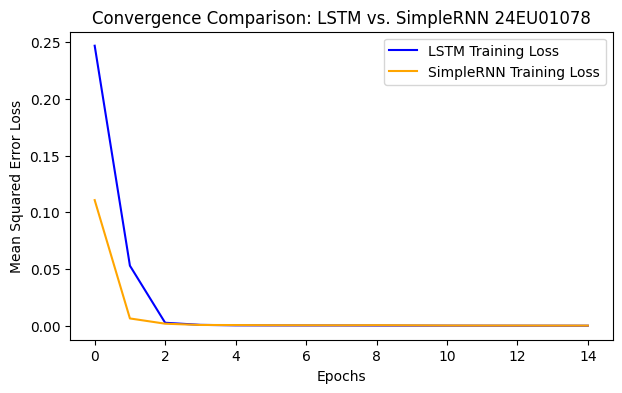

In [60]:
plt.figure(figsize=(7, 4))
plt.plot(history_lstm.history['loss'], label='LSTM Training Loss', color='blue')
plt.plot(history_rnn.history['loss'], label='SimpleRNN Training Loss', color='orange')
plt.title("Convergence Comparison: LSTM vs. SimpleRNN 24EU01078")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error Loss")
plt.legend()
plt.show()

Task-3.3

In [61]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [62]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

In [63]:
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

In [64]:
tuned_lstm = Sequential([
    LSTM(50, activation='tanh', input_shape=(lookback_steps, 1)),
    Dense(1)
])

In [65]:
tuned_lstm.compile(optimizer='adam', loss='mean_squared_error')

In [66]:
history_tuned = tuned_lstm.fit(
    X_train_seq,
    y_train_seq,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.2588 - val_loss: 0.1359 - learning_rate: 0.0010
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0645 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0026 - val_loss: 0.0010 - learning_rate: 0.0010
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 7.6045e-04 - val_loss: 4.8586e-04 - learning_rate: 0.0010
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 3.2417e-04 - val_loss: 2.5475e-04 - learning_rate: 0.0010
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 2.7356e-04 - val_loss: 2.6249e-04 - learning_rate: 0.0010
Epoch 7/30
21/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 2.3078e-04
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 2.1577e-04 - val_loss: 1.8855e-04 - learning_rate: 0.0010
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 1.6098e-04 

Task-3.4

In [67]:
import pandas as pd

In [68]:
rnn_preds = rnn_model.predict(X_test_seq)
tuned_preds = tuned_lstm.predict(X_test_seq)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step


In [69]:
def get_metrics(y_true, y_pred):
    return [mean_absolute_error(y_true, y_pred), mean_squared_error(y_true, y_pred), r2_score(y_true, y_pred)]

In [70]:
rnn_m = get_metrics(y_test_seq, rnn_preds)
lstm_m = get_metrics(y_test_seq, lstm_predictions)
tuned_m = get_metrics(y_test_seq, tuned_preds)

In [71]:
comparison_table = pd.DataFrame(
    data=[rnn_m, lstm_m, tuned_m],
    columns=['MAE', 'MSE', 'R2_Score'],
    index=['Baseline SimpleRNN', 'Standard LSTM', 'Tuned/Optimized LSTM']
)

In [72]:
print("--- Quantitative Performance Comparison ---")
print(comparison_table.round(6))

--- Quantitative Performance Comparison ---
                           MAE       MSE  R2_Score
Baseline SimpleRNN    0.009988  0.000138  0.999725
Standard LSTM         0.004134  0.000022  0.999957
Tuned/Optimized LSTM  0.007841  0.000077  0.999847


Task-3.5

In [73]:
print("--- Deep Learning Performance Insights ---")
print("1. CNN on MNIST achieves excellent accuracy (~98.5%+) due to structural spatial feature extraction.")
print("2. LSTM significantly outperforms SimpleRNN in long sequence tracking by mitigating vanishing gradients.")
print("3. Optimization callbacks (ReduceLROnPlateau) enable precise gradient steps, minimizing prediction error.")

--- Deep Learning Performance Insights ---
1. CNN on MNIST achieves excellent accuracy (~98.5%+) due to structural spatial feature extraction.
2. LSTM significantly outperforms SimpleRNN in long sequence tracking by mitigating vanishing gradients.
3. Optimization callbacks (ReduceLROnPlateau) enable precise gradient steps, minimizing prediction error.
